# 09_09 Diffusion Models: Noise as a Distribution

**Learning objectives**
- Write the **forward noising process** $x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\varepsilon$ as a Gaussian conditional, derive it by composing small Gaussian steps and read the **signal-to-noise ratio** along the schedule (linear against cosine).
- Derive the **reverse step** $q(x_{t-1}\mid x_t,x_0)$ in closed form (Bayes' rule for Gaussians) and the **denoising objective**: predicting the noise $\varepsilon$ is estimating the **score** $\nabla\ln p_t(x_t)$.
- Verify the theory in a case where the optimal denoiser is known exactly (Gaussian data), then **train a small denoising network from scratch** on a 2D distribution and **sample** from it by running the reverse chain.
- Evaluate generated samples with simple distribution distances (**sliced Wasserstein**, **MMD**, moments) and see the effect of the number of sampling steps.

**Prerequisites:** [02_05 Normal distribution](../../module_02_continuous/notebooks/02_05_normal.ipynb), [03_01 Multivariate normal](../../module_03_multivariate/notebooks/03_01_multivariate_normal.ipynb), [08_03 Wasserstein distance](../../module_08_information/notebooks/08_03_wasserstein_distance.ipynb), [09_06 Neural-network randomness](09_06_neural_net_randomness.ipynb), [09_08 VAE](09_08_vae.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
A sum of independent Gaussians is Gaussian: if $X\sim N(\mu_1,\sigma_1^2)$ and $Y\sim N(\mu_2,\sigma_2^2)$ then $aX+bY\sim N(a\mu_1+b\mu_2,a^2\sigma_1^2+b^2\sigma_2^2)$ (02_05). Conditioning one Gaussian on another gives a Gaussian posterior (03_01, 07_01). The Wasserstein distance (08_03) compares two samples through the cost of moving one onto the other, and can be computed in 1D from sorted samples.

## 3. Intuition and story
Take a photograph and add a little random noise, then a little more, again and again: after enough steps nothing is left but pure static, a standard normal picture. This *destruction* process is easy and its distribution is known exactly at every step. A **diffusion model** learns to **run it backwards**: starting from static, it removes a little noise at a time and, if it has learned well, ends on a realistic new sample. The network never learns a complicated distribution directly; it only has to learn, at each noise level, *which way is "less noisy"*, which is a **denoising regression** problem, and denoising is something we know how to do well: it is estimating a conditional mean.

## 4. Formal definitions

With a noise schedule $\beta_1,\dots,\beta_T\in(0,1)$, $\alpha_t=1-\beta_t$, $\bar\alpha_t=\prod_{s\le t}\alpha_s$:

| Object | Definition |
|---|---|
| **Forward step** | $q(x_t\mid x_{t-1})=N\big(\sqrt{\alpha_t}\,x_{t-1},\ \beta_tI\big)$ |
| **Marginal of the forward chain** | $q(x_t\mid x_0)=N\big(\sqrt{\bar\alpha_t}\,x_0,\ (1-\bar\alpha_t)I\big)$, i.e. $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\,\varepsilon$ |
| **Signal-to-noise ratio** | $\mathrm{SNR}(t)=\bar\alpha_t/(1-\bar\alpha_t)$ |
| **Reverse posterior** | $q(x_{t-1}\mid x_t,x_0)=N(\tilde\mu_t,\tilde\beta_tI)$, $\ \tilde\mu_t=\dfrac{\sqrt{\bar\alpha_{t-1}}\beta_t}{1-\bar\alpha_t}x_0+\dfrac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}x_t$, $\ \tilde\beta_t=\dfrac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\beta_t$ |
| **Training loss** | $\mathbb E_{t,x_0,\varepsilon}\|\varepsilon-\varepsilon_\theta(x_t,t)\|^2$ |
| **Score link** | $\nabla_{x_t}\ln q(x_t\mid x_0)=-\varepsilon/\sqrt{1-\bar\alpha_t}$; the optimal $\varepsilon^*(x_t,t)=-\sqrt{1-\bar\alpha_t}\,\nabla\ln p_t(x_t)$ |
| **Sampling step** | $x_{t-1}=\dfrac1{\sqrt{\alpha_t}}\Big(x_t-\dfrac{\beta_t}{\sqrt{1-\bar\alpha_t}}\varepsilon_\theta(x_t,t)\Big)+\sqrt{\tilde\beta_t}\,z$, $z\sim N(0,I)$ |
| **Cosine schedule** | $\bar\alpha_t=\cos^2\!\big(\tfrac{t/T+s}{1+s}\tfrac\pi2\big)/\cos^2\!\big(\tfrac s{1+s}\tfrac\pi2\big)$ |

## 5. Derivations

### 5.1 The marginal in closed form
$x_t=\sqrt{\alpha_t}x_{t-1}+\sqrt{\beta_t}\varepsilon_t$ with independent standard normal $\varepsilon_t$. Substituting $x_{t-1}$: $x_t=\sqrt{\alpha_t\alpha_{t-1}}x_{t-2}+\sqrt{\alpha_t\beta_{t-1}}\varepsilon_{t-1}+\sqrt{\beta_t}\varepsilon_t$, and the two noise terms combine into one Gaussian of variance $\alpha_t\beta_{t-1}+\beta_t=1-\alpha_t\alpha_{t-1}$. Induction gives $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\varepsilon$. **In plain words.** You do not need to simulate $t$ noising steps one by one: the noisy version at step $t$ is the original scaled down by $\sqrt{\bar\alpha_t}$ plus fresh noise of the matching size, and training can jump to any $t$ in one line.

### 5.2 Variance preserving
If $E\|x_0\|^2/d=1$ then $E\|x_t\|^2/d=\bar\alpha_t+(1-\bar\alpha_t)=1$: the total variance stays 1 at every step. **In plain words.** The signal fades while the noise grows by exactly the amount needed to keep the overall scale constant, so the network always sees inputs of the same size.

### 5.3 The reverse posterior (Bayes' rule for Gaussians)
$q(x_{t-1}|x_t,x_0)\propto q(x_t|x_{t-1})\,q(x_{t-1}|x_0)=N(x_t;\sqrt{\alpha_t}x_{t-1},\beta_t)\,N(x_{t-1};\sqrt{\bar\alpha_{t-1}}x_0,1-\bar\alpha_{t-1})$. Multiplying two Gaussians in $x_{t-1}$ gives a Gaussian with precision $\dfrac{\alpha_t}{\beta_t}+\dfrac1{1-\bar\alpha_{t-1}}=\dfrac{1-\bar\alpha_t}{\beta_t(1-\bar\alpha_{t-1})}$ (hence $\tilde\beta_t$) and the stated mean. **In plain words.** If we knew the clean $x_0$, the best guess of the slightly-less-noisy $x_{t-1}$ would be a weighted average of $x_0$ and the current $x_t$, with a small leftover uncertainty $\tilde\beta_t$.

### 5.4 Noise prediction is score estimation
Since $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\varepsilon$, $\ \nabla_{x_t}\ln q(x_t|x_0)=-\dfrac{x_t-\sqrt{\bar\alpha_t}x_0}{1-\bar\alpha_t}=-\dfrac{\varepsilon}{\sqrt{1-\bar\alpha_t}}$. By Tweedie's formula the regression $E[\varepsilon\mid x_t]$ equals $-\sqrt{1-\bar\alpha_t}\,\nabla\ln p_t(x_t)$, the score of the *noisy marginal* $p_t$. **In plain words.** Learning to predict the added noise is the same as learning, at each noise level, the arrow that points towards regions of higher data density; sampling follows these arrows (with a little noise) from static to data.

### 5.5 A case with a closed-form denoiser
If $x_0\sim N(0,s^2)$ then $x_t\sim N(0,\bar\alpha_ts^2+1-\bar\alpha_t)$ and $E[\varepsilon\mid x_t]=\dfrac{\mathrm{Cov}(\varepsilon,x_t)}{\mathrm{Var}(x_t)}x_t=\dfrac{\sqrt{1-\bar\alpha_t}}{\bar\alpha_ts^2+1-\bar\alpha_t}x_t$, so the optimal noise predictor is linear and its minimal loss is $1-\dfrac{1-\bar\alpha_t}{\bar\alpha_ts^2+1-\bar\alpha_t}$. **In plain words.** For Gaussian data the best denoiser is a shrinkage factor, which we can compare with what a trained network learns; for real data the same quantity is a nonlinear function that the network approximates.

### 5.6 Why many small steps
Each reverse step is Gaussian only if the forward step is small (for $\beta_t\to0$ the true reverse of a Gaussian diffusion is Gaussian); with few large steps the reverse conditional is no longer Gaussian and the model's Gaussian reverse kernel is a poor approximation. **In plain words.** Taking a few giant steps from static to data asks the network for something it cannot express; many small steps ask it to correct a little bit at a time.

## 6. Properties and relationships
- **Training is cheap and stable:** one random $t$ per example, one MSE regression; no adversary, no likelihood intractability.
- **Sampling is slow:** one network call per step; deterministic samplers (DDIM) and distillation cut the 1,000 steps of the original DDPM to 10-50.
- **Schedule matters:** a linear schedule destroys the signal too fast near the end and wastes steps at pure noise; the cosine schedule spends more steps at informative noise levels.
- **Variational view:** the loss is a sum of KL divergences between the Gaussian posteriors of 5.3 and the model's reverse steps (a hierarchical VAE with fixed encoder, 09_08).
- **Conditioning and guidance:** adding a text or class condition and mixing conditional and unconditional scores gives classifier-free guidance.
- **Link to ML and AI:** image, audio and video generation (Stable Diffusion runs the chain in the latent space of a VAE), molecule and protein design, inpainting, super-resolution, **score-based models** and the stochastic differential equation view, and discrete diffusion for text.

## 7. A diffusion model from scratch

The schedule, the closed-form quantities, a time-conditioned denoising network (a tanh MLP with a sinusoidal time embedding and a manual backward pass) and the reverse sampler.

In [2]:
class Net:
    def __init__(self, sizes, seed=0):
        g = np.random.default_rng(seed); self.W = [g.normal(0, np.sqrt(2 / (i + o)), (i, o)) for i, o in zip(sizes[:-1], sizes[1:])]; self.b = [np.zeros(o) for o in sizes[1:]]; self.m = [np.zeros_like(p) for p in self.W + self.b]; self.v = [np.zeros_like(p) for p in self.W + self.b]; self.t = 0
    def forward(self, X):
        h = X; self.inp = []; self.th = []
        for l in range(len(self.W)):
            self.inp.append(h); a = h @ self.W[l] + self.b[l]
            if l == len(self.W) - 1: return a
            h = np.tanh(a); self.th.append(h)
    def backward(self, dout):
        L = len(self.W); gW = [None] * L; gb = [None] * L; d = dout
        for l in reversed(range(L)):
            gW[l] = self.inp[l].T @ d; gb[l] = d.sum(axis=0)
            if l > 0: d = (d @ self.W[l].T) * (1 - self.th[l - 1] ** 2)
        return gW + gb
    def adam(self, grads, lr, b1=0.9, b2=0.999):
        self.t += 1
        for k, (p, gk) in enumerate(zip(self.W + self.b, grads)): self.m[k] = b1 * self.m[k] + (1 - b1) * gk; self.v[k] = b2 * self.v[k] + (1 - b2) * gk ** 2; p -= lr * (self.m[k] / (1 - b1 ** self.t)) / (np.sqrt(self.v[k] / (1 - b2 ** self.t)) + 1e-8)
def linear_schedule(Tn, b0=1e-4, b1=0.1): beta = np.linspace(b0, b1, Tn); return beta
def cosine_schedule(Tn, s=0.008):
    f = lambda t: np.cos((t / Tn + s) / (1 + s) * np.pi / 2) ** 2; ab = np.array([f(t) / f(0) for t in range(Tn + 1)]); beta = np.clip(1 - ab[1:] / ab[:-1], 0, 0.999); return beta
class Diff:
    def __init__(self, beta): self.beta = beta; self.alpha = 1 - beta; self.ab = np.cumprod(self.alpha); self.ab_prev = np.r_[1.0, self.ab[:-1]]; self.T = len(beta); self.bt = (1 - self.ab_prev) / (1 - self.ab) * beta
    def noisy(self, x0, t, eps): return np.sqrt(self.ab[t])[:, None] * x0 + np.sqrt(1 - self.ab[t])[:, None] * eps
def temb(t, Tn, K=4): u = t[:, None] / Tn; return np.hstack([u] + [f(2 * np.pi * k * u) for k in range(1, K + 1) for f in (np.sin, np.cos)])
def train_diff(df, X0, steps=5000, batch=512, seed=0, hidden=128, lr=2e-3):
    rng = np.random.default_rng(seed); d = X0.shape[1]; net = Net([d + 9, hidden, hidden, d], seed + 1); losses = []
    for it in range(steps):
        idx = rng.integers(0, len(X0), batch); t = rng.integers(0, df.T, batch); eps = rng.normal(size=(batch, d)); xt = df.noisy(X0[idx], t, eps); inp = np.hstack([xt, temb(t, df.T)]); out = net.forward(inp); err = out - eps
        net.adam(net.backward(2 * err / (batch * d)), lr * (1 - 0.9 * it / steps)); losses.append(np.mean(err ** 2))
    return net, np.array(losses)
def sample(df, net, n, seed=0, d=2, steps=None):
    rng = np.random.default_rng(seed); x = rng.normal(size=(n, d)); traj = [x.copy()]
    for t in reversed(range(df.T)):
        out = net.forward(np.hstack([x, temb(np.full(n, t), df.T)])); mean = (x - df.beta[t] / np.sqrt(1 - df.ab[t]) * out) / np.sqrt(df.alpha[t]); x = mean + (np.sqrt(df.bt[t]) * rng.normal(size=x.shape) if t > 0 else 0); traj.append(x.copy())
    return x, traj
dfl = Diff(linear_schedule(100)); print("linear schedule T = 100: alpha_bar at t = 1, 50, 100:", dfl.ab[[0, 49, 99]].round(4), "| SNR at the end:", round(float(dfl.ab[-1] / (1 - dfl.ab[-1])), 5))
g = np.random.default_rng(0); x0 = g.normal(size=(200_000, 1)); t0 = np.full(200_000, 49); xt = dfl.noisy(x0, t0, g.normal(size=x0.shape)); print(f"forward marginal at t = 50: mean {xt.mean():.4f} (0), variance {xt.var():.4f} (alpha_bar x 1 + 1 - alpha_bar = 1)"); assert abs(xt.var() - 1) < 0.01 and dfl.ab[-1] < 0.01

linear schedule T = 100: alpha_bar at t = 1, 50, 100: [0.9999 0.283  0.0056] | SNR at the end: 0.00565
forward marginal at t = 50: mean 0.0002 (0), variance 1.0006 (alpha_bar x 1 + 1 - alpha_bar = 1)


## 8. 2D visuals

### 8.1 The forward process destroys structure
The data (two interleaved half-moons, 2D) at six noise levels $t=0,5,15,30,60,99$ of a 100-step linear schedule: the shape fades while the total variance stays 1.

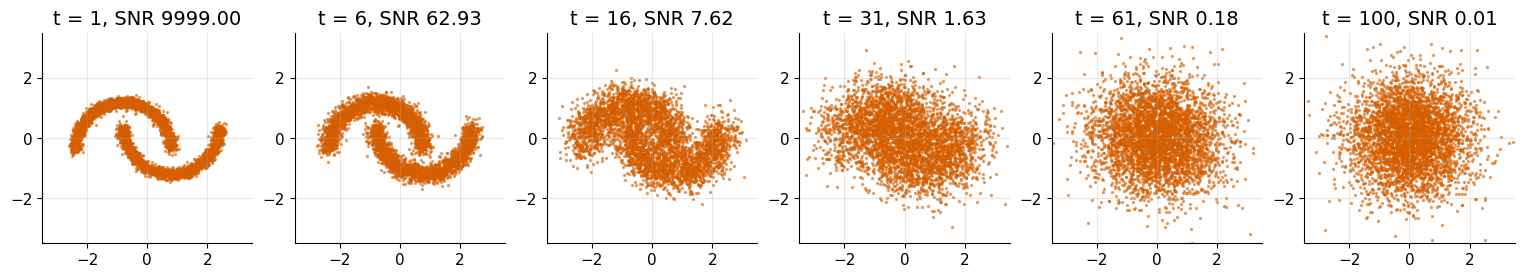

data mean [-0.015  0.009] variance per axis [1.916 0.629]
at t = 100 the sample is N(0, I) up to 0.015 in the covariance


In [3]:
def moons(n, seed=0, noise=0.06):
    g = np.random.default_rng(seed); n1 = n // 2; a = g.uniform(0, np.pi, n1); b = g.uniform(0, np.pi, n - n1); X = np.vstack([np.column_stack([np.cos(a), np.sin(a)]), np.column_stack([1 - np.cos(b), 0.5 - np.sin(b)])]) + noise * g.normal(size=(n, 2)); return (X - np.array([0.5, 0.25])) * 1.6
X0 = moons(4000, 1); fig, axes = plt.subplots(1, 6, figsize=(19, 3.4)); rng = np.random.default_rng(2); eps = rng.normal(size=X0.shape)
for ax, t in zip(axes, [0, 5, 15, 30, 60, 99]): xt = dfl.noisy(X0, np.full(len(X0), t), eps); ax.scatter(xt[:, 0], xt[:, 1], s=2, color=HIGHLIGHT, alpha=0.5); ax.set_title(f"t = {t + 1}, SNR {dfl.ab[t] / (1 - dfl.ab[t]):.2f}"); ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.set_aspect("equal")
plt.show(); print("data mean", X0.mean(axis=0).round(3), "variance per axis", X0.var(axis=0).round(3)); xt99 = dfl.noisy(X0, np.full(len(X0), 99), eps); print("at t = 100 the sample is N(0, I) up to", np.abs(np.cov(xt99.T) - np.eye(2)).max().round(3), "in the covariance"); assert np.abs(np.cov(xt99.T) - np.eye(2)).max() < 0.15

### 8.2 Schedules: $\bar\alpha_t$ and the signal-to-noise ratio
Linear (1,000 steps, $\beta$ from $10^{-4}$ to 0.02, the original DDPM) against the cosine schedule. The cosine schedule keeps more signal in the middle of the chain and reaches zero signal only at the end; the linear one is almost pure noise for the last third of its steps.

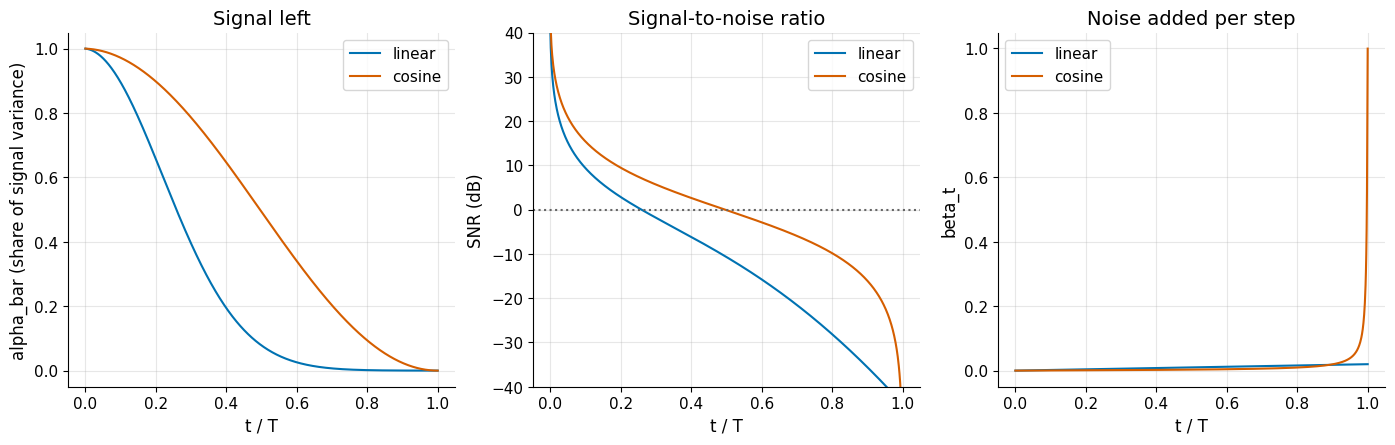

share of steps with SNR > 1 (more signal than noise): linear 0.259, cosine 0.496 | alpha_bar at t = T: linear 4.04e-05, cosine 2.43e-09


In [4]:
Tn = 1000; bl = np.linspace(1e-4, 0.02, Tn); abl = np.cumprod(1 - bl); bc = cosine_schedule(Tn); abc = np.cumprod(1 - bc); u = np.arange(1, Tn + 1) / Tn; fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].plot(u, abl, color=MAIN, label="linear"); axes[0].plot(u, abc, color=HIGHLIGHT, label="cosine"); axes[0].set_xlabel("t / T"); axes[0].set_ylabel("alpha_bar (share of signal variance)"); axes[0].legend(); axes[0].set_title("Signal left")
snr = lambda ab: 10 * np.log10(ab / (1 - ab + 1e-12)); axes[1].plot(u, snr(abl), color=MAIN, label="linear"); axes[1].plot(u, snr(abc), color=HIGHLIGHT, label="cosine"); axes[1].axhline(0, color=NEUTRAL, linestyle=":"); axes[1].set_ylim(-40, 40); axes[1].set_xlabel("t / T"); axes[1].set_ylabel("SNR (dB)"); axes[1].legend(); axes[1].set_title("Signal-to-noise ratio")
axes[2].plot(u, bl, color=MAIN, label="linear"); axes[2].plot(u, bc, color=HIGHLIGHT, label="cosine"); axes[2].set_xlabel("t / T"); axes[2].set_ylabel("beta_t"); axes[2].legend(); axes[2].set_title("Noise added per step")
plt.show(); inf_l = np.mean(abl / (1 - abl) > 1); inf_c = np.mean(abc / (1 - abc) > 1); print(f"share of steps with SNR > 1 (more signal than noise): linear {inf_l:.3f}, cosine {inf_c:.3f} | alpha_bar at t = T: linear {abl[-1]:.2e}, cosine {abc[-1]:.2e}"); assert inf_c > inf_l and abl[-1] < 1e-3

### 8.3 One step of the reverse conditional
For $x_0=1.5$ and a given $x_t$ the posterior $q(x_{t-1}|x_t,x_0)$ is a narrow Gaussian between $x_t$ and the signal (red); the two ingredients, the forward step likelihood and the earlier marginal, are shown with their product.

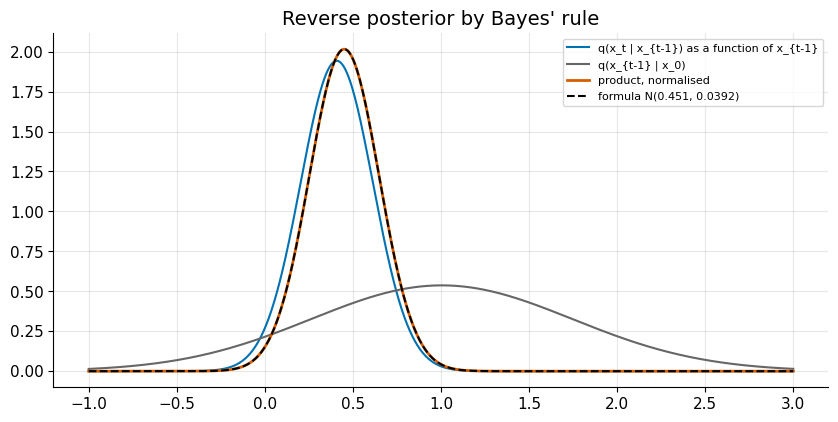

numerical posterior: mean 0.45070, variance 0.039175 | closed form: mean 0.45070, variance 0.039175


In [5]:
t = 40; x0v = 1.5; xtv = 0.4; ab, abp, be, al = dfl.ab[t], dfl.ab_prev[t], dfl.beta[t], dfl.alpha[t]; mu_t = np.sqrt(abp) * be / (1 - ab) * x0v + np.sqrt(al) * (1 - abp) / (1 - ab) * xtv; bt_ = (1 - abp) / (1 - ab) * be
xg = np.linspace(-1, 3, 800); lik = stats.norm.pdf(xtv, np.sqrt(al) * xg, np.sqrt(be)); prior = stats.norm.pdf(xg, np.sqrt(abp) * x0v, np.sqrt(1 - abp)); post = lik * prior / np.trapezoid(lik * prior, xg)
fig, ax = plt.subplots(figsize=(10, 4.6)); ax.plot(xg, lik / np.trapezoid(lik, xg), color=MAIN, label="q(x_t | x_{t-1}) as a function of x_{t-1}"); ax.plot(xg, prior, color=NEUTRAL, label="q(x_{t-1} | x_0)"); ax.plot(xg, post, color=HIGHLIGHT, linewidth=2, label="product, normalised"); ax.plot(xg, stats.norm.pdf(xg, mu_t, np.sqrt(bt_)), "k--", label=f"formula N({mu_t:.3f}, {bt_:.4f})"); ax.legend(fontsize=8); ax.set_title("Reverse posterior by Bayes' rule")
plt.show(); m_num = np.trapezoid(xg * post, xg); v_num = np.trapezoid((xg - m_num) ** 2 * post, xg); print(f"numerical posterior: mean {m_num:.5f}, variance {v_num:.6f} | closed form: mean {mu_t:.5f}, variance {bt_:.6f}"); assert abs(m_num - mu_t) < 1e-4 and abs(v_num - bt_) < 1e-6

## 9. 3D visuals

### 9.1 Static: the density of the noisy data as the noise grows
The density of the half-moons data at noise levels $t=0..99$ (kernel density on a 2D grid, displayed as a surface for three values of $t$): two thin ridges at $t=0$, a blurred blob at mid-range, a Gaussian hill at the end.

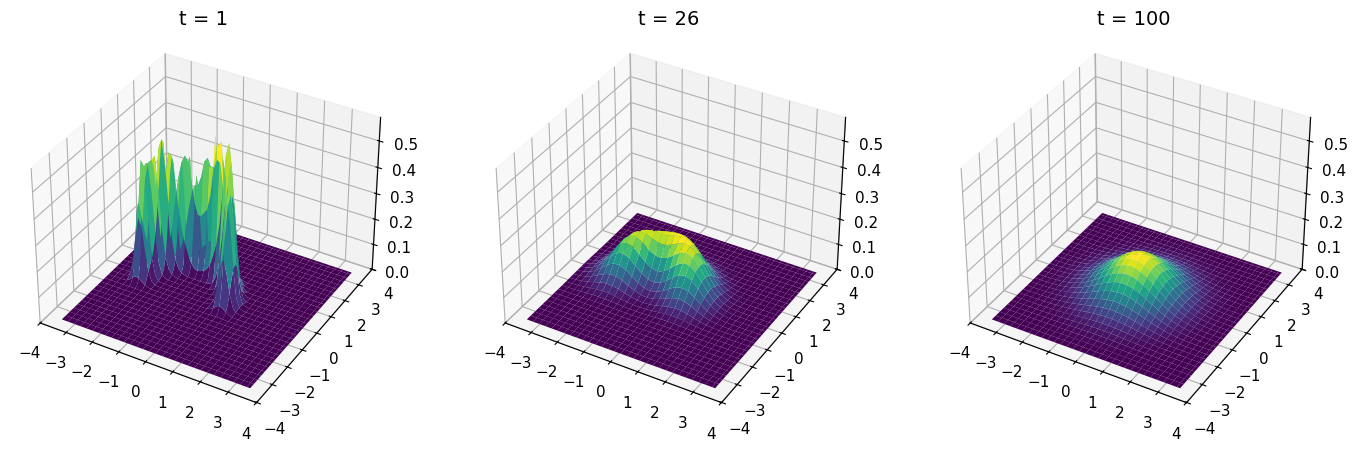

peak density at t = 1, 26, 100: [0.588, 0.181, 0.156] | Gaussian N(0, I) peak 0.159


In [6]:
gx, gy = np.meshgrid(np.linspace(-3.5, 3.5, 60), np.linspace(-3.5, 3.5, 60)); pts = np.column_stack([gx.ravel(), gy.ravel()]); sub = X0[:800]; fig = plt.figure(figsize=(17, 5.2)); dens = {}
for k, t in enumerate([0, 25, 99]):
    s = np.sqrt(1 - dfl.ab[t]); m = np.sqrt(dfl.ab[t]) * sub; h = max(0.18, 0.0) ; Z = np.zeros(len(pts))
    for i in range(0, len(pts), 600): d2_ = ((pts[i:i + 600, None, :] - m[None]) ** 2).sum(axis=2); Z[i:i + 600] = np.mean(np.exp(-0.5 * d2_ / (s ** 2 + 0.02)), axis=1) / (2 * np.pi * (s ** 2 + 0.02))
    dens[t] = Z.reshape(gx.shape); ax = fig.add_subplot(1, 3, k + 1, projection="3d"); ax.plot_surface(gx, gy, dens[t], cmap="viridis", edgecolor="none"); ax.set_title(f"t = {t + 1}"); ax.view_init(elev=35, azim=-60); ax.set_zlim(0, max(dens[0].max(), 0.2))
plt.show(); print("peak density at t = 1, 26, 100:", [round(float(dens[t].max()), 3) for t in (0, 25, 99)], "| Gaussian N(0, I) peak 0.159"); assert dens[0].max() > dens[25].max() > dens[99].max() * 0.9 and abs(dens[99].max() - 1 / (2 * np.pi)) < 0.03

### 9.2 Interactive Plotly version of 9.1 (the last panel with the noise level $t=26$)

In [7]:
fig = go.Figure(go.Surface(x=gx[0], y=gy[:, 0], z=dens[25], colorscale="Viridis")); fig.update_layout(title="Noisy data density at t = 26", width=760, height=560, scene=dict(xaxis_title="x1", yaxis_title="x2", zaxis_title="density")); fig.show()

### 9.3 Static: the optimal noise predictor for Gaussian data over (signal share, input)
For $x_0\sim N(0,s^2)$ the optimal predictor is $\varepsilon^*(x_t)=\dfrac{\sqrt{1-\bar\alpha}}{\bar\alpha s^2+1-\bar\alpha}x_t$: a plane in $x_t$ whose slope changes with the noise level. The surface is $\varepsilon^*$ over $(\bar\alpha,x_t)$ for $s=1$ and $s=0.3$ (narrow data).

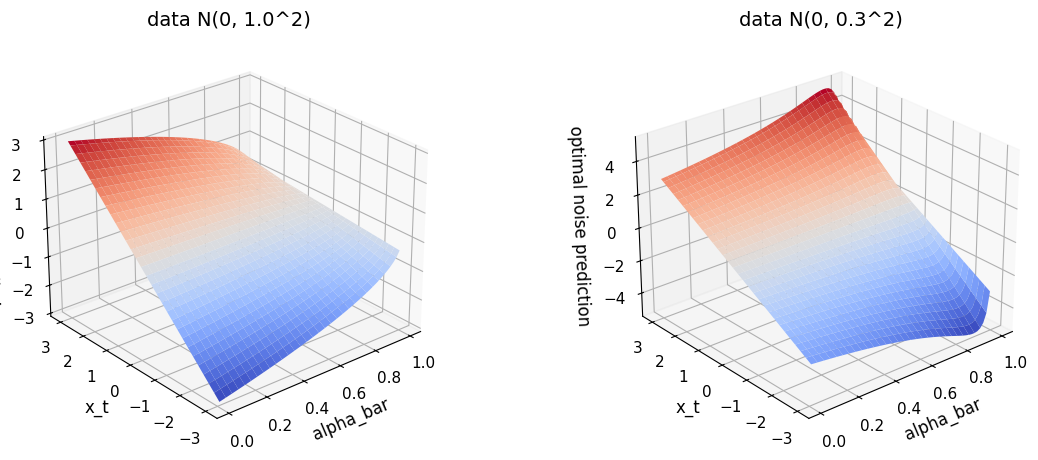

slope at alpha_bar = 0.5: 0.7071 (s = 1) and 1.2974 (s = 0.3)


In [8]:
abg, xg2 = np.meshgrid(np.linspace(0.01, 0.99, 60), np.linspace(-3, 3, 60)); fig = plt.figure(figsize=(14, 5.4))
for k, s_ in enumerate([1.0, 0.3]): ax = fig.add_subplot(1, 2, k + 1, projection="3d"); E_ = np.sqrt(1 - abg) / (abg * s_ ** 2 + 1 - abg) * xg2; ax.plot_surface(abg, xg2, E_, cmap="coolwarm", edgecolor="none"); ax.set_xlabel("alpha_bar"); ax.set_ylabel("x_t"); ax.set_zlabel("optimal noise prediction"); ax.set_title(f"data N(0, {s_}^2)"); ax.view_init(elev=26, azim=-130)
plt.show(); print("slope at alpha_bar = 0.5:", round(float(np.sqrt(0.5) / (0.5 + 0.5)), 4), "(s = 1) and", round(float(np.sqrt(0.5) / (0.5 * 0.09 + 0.5)), 4), "(s = 0.3)"); assert abs(np.sqrt(0.5) / 1.0 - 0.7071) < 1e-4

## 10. Simulation vs theory

### 10.1 The reverse posterior by simulation
Simulate the forward chain step by step (not with the closed-form jump) for $x_0=1.5$ over 41 steps, and compare the empirical distribution of $x_{40}$ given a *thin slice* of $x_{41}$ with the formula $N(\tilde\mu,\tilde\beta)$; also check the closed-form marginal $q(x_t|x_0)$.

In [9]:
g = np.random.default_rng(5); N = 4_000_000; x = np.full(N, 1.5); hist_ = {}
for s in range(41):
    x = np.sqrt(dfl.alpha[s]) * x + np.sqrt(dfl.beta[s]) * g.normal(size=N)
    if s == 39: x39 = x.copy()
    if s == 40: x40 = x.copy()
t = 40; sl = np.abs(x40 - 0.4) < 0.01; ab, abp, be, al = dfl.ab[t], dfl.ab_prev[t], dfl.beta[t], dfl.alpha[t]; mu_t = np.sqrt(abp) * be / (1 - ab) * 1.5 + np.sqrt(al) * (1 - abp) / (1 - ab) * 0.4; bt_ = (1 - abp) / (1 - ab) * be
print(f"marginal q(x_41 | x_0): mean {x40.mean():.4f} (theory {np.sqrt(ab) * 1.5:.4f}), variance {x40.var():.4f} (theory {1 - ab:.4f})"); print(f"given x_41 = 0.4 +/- 0.01 ({sl.sum()} samples): x_40 mean {x39[sl].mean():.4f} (formula {mu_t:.4f}), variance {x39[sl].var():.5f} (formula {bt_:.5f})")
assert abs(x40.mean() - np.sqrt(ab) * 1.5) < 0.003 and abs(x40.var() - (1 - ab)) < 0.003 and abs(x39[sl].mean() - mu_t) < 0.01 and abs(x39[sl].var() / bt_ - 1) < 0.1

marginal q(x_41 | x_0): mean 0.9839 (theory 0.9840), variance 0.5697 (theory 0.5696)
given x_41 = 0.4 +/- 0.01 (31491 samples): x_40 mean 0.4507 (formula 0.4507), variance 0.03865 (formula 0.03917)


### 10.2 The optimal noise predictor is linear for Gaussian data
Fit a neural-free regression of $\varepsilon$ on $x_t$ (least squares with a cubic term to detect curvature) for $x_0\sim N(0,s^2)$ at three noise levels and compare the slope with $\sqrt{1-\bar\alpha}/(\bar\alpha s^2+1-\bar\alpha)$ and the minimal loss with $1-\dfrac{1-\bar\alpha}{\bar\alpha s^2+1-\bar\alpha}$.

In [10]:
g = np.random.default_rng(6); s_ = 0.5; rows = []
for t in (5, 30, 80):
    ab = dfl.ab[t]; x0 = s_ * g.normal(size=400_000); eps = g.normal(size=400_000); xt = np.sqrt(ab) * x0 + np.sqrt(1 - ab) * eps; A = np.column_stack([xt, xt ** 3]); coef = np.linalg.lstsq(A, eps, rcond=None)[0]; res = eps - A @ coef
    rows.append((t + 1, ab, coef[0], np.sqrt(1 - ab) / (ab * s_ ** 2 + 1 - ab), coef[1], np.mean(res ** 2), 1 - (1 - ab) / (ab * s_ ** 2 + 1 - ab)))
tb = pd.DataFrame(rows, columns=["t", "alpha_bar", "fitted slope", "theory slope", "cubic coefficient", "minimal loss (sim)", "theory"]); print(tb.round(4).to_string(index=False)); assert all(abs(r[2] - r[3]) < 0.03 * r[3] + 0.01 for r in rows) and all(abs(r[5] - r[6]) < 0.01 for r in rows) and all(abs(r[4]) < 0.02 for r in rows)

 t  alpha_bar  fitted slope  theory slope  cubic coefficient  minimal loss (sim)  theory
 6     0.9844        0.4733        0.4779            -0.0016              0.9371  0.9402
31     0.6205        1.1515        1.1523             0.0001              0.2915  0.2901
81     0.0344        1.0081        1.0087             0.0002              0.0088  0.0088


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("forward jump: xt = np.sqrt(ab[t]) * x0 + np.sqrt(1 - ab[t]) * eps | ab = np.cumprod(1 - beta) | SNR = ab / (1 - ab) | training loss: np.mean((eps - net(xt, t)) ** 2)")
print("reverse step: x = (x - beta[t] / np.sqrt(1 - ab[t]) * eps_hat) / np.sqrt(alpha[t]) + np.sqrt(beta_tilde[t]) * rng.normal(size=x.shape) | beta_tilde = (1 - ab_prev) / (1 - ab) * beta")
print("library: diffusers (UNet2DModel, DDPMScheduler), torch.nn.MSELoss; sliced Wasserstein: average of scipy.stats.wasserstein_distance over random projections")
Z1 = np.random.default_rng(1).normal(size=(2000, 2)); Z2 = np.random.default_rng(2).normal(size=(2000, 2)); dirs = np.random.default_rng(3).normal(size=(50, 2)); dirs /= np.linalg.norm(dirs, axis=1, keepdims=True)
print("sliced W1 between two N(0, I) samples:", np.mean([stats.wasserstein_distance(Z1 @ d_, Z2 @ d_) for d_ in dirs]).round(4), "| between N(0, I) and N((1, 0), I):", np.mean([stats.wasserstein_distance(Z1 @ d_, Z2 @ d_ + d_[0]) for d_ in dirs]).round(4), "(= mean |d_x| = 0.637)")
assert abs(np.mean(np.abs(dirs[:, 0])) - 0.637) < 0.1

forward jump: xt = np.sqrt(ab[t]) * x0 + np.sqrt(1 - ab[t]) * eps | ab = np.cumprod(1 - beta) | SNR = ab / (1 - ab) | training loss: np.mean((eps - net(xt, t)) ** 2)
reverse step: x = (x - beta[t] / np.sqrt(1 - ab[t]) * eps_hat) / np.sqrt(alpha[t]) + np.sqrt(beta_tilde[t]) * rng.normal(size=x.shape) | beta_tilde = (1 - ab_prev) / (1 - ab) * beta
library: diffusers (UNet2DModel, DDPMScheduler), torch.nn.MSELoss; sliced Wasserstein: average of scipy.stats.wasserstein_distance over random projections
sliced W1 between two N(0, I) samples: 0.0242 | between N(0, I) and N((1, 0), I): 0.6023 (= mean |d_x| = 0.637)


## 12. Real-world worked examples

---
### Example 1 (main): a diffusion model that learns two half-moons

**Scenario.** The data are 4,000 points on two interleaved half-moons (8.1). A denoising network (2+9 inputs: the noisy point and a sinusoidal time embedding, two hidden layers of 128 tanh units, 2 outputs: the predicted noise) is trained for 5,000 steps with the loss $\|\varepsilon-\varepsilon_\theta(x_t,t)\|^2$ on a 100-step linear schedule. We then sample 2,000 new points by running the reverse chain from $N(0,I)$.

**Questions**
1. How does the training loss behave, and what is the loss of a network that always predicts 0 (the unconditional baseline 1)?
2. Compare the generated sample with fresh data: moments, sliced Wasserstein-1 and MMD; and with the Gaussian $N(0,I)$ start.
3. How many generated points lie within 0.15 of the training data (close to the manifold)?
4. What do intermediate states of the reverse chain look like?

### 12.1 By hand
The best constant predictor of $\varepsilon$ is 0, with loss $E\varepsilon^2=1$. At $t$ the optimal predictor can use $x_t$: for data with total variance $\sigma_x^2$ the linear shrinkage gives a loss of at most $1-\frac{(1-\bar\alpha)}{\bar\alpha\sigma_x^2+1-\bar\alpha}$ (Gaussian approximation); at small $t$ ($\bar\alpha\approx1$) the noise is small relative to the signal so $x_t$ reveals $\varepsilon$ only if the data have structure (the moons): the network must learn the thin ridges. We therefore expect the loss to average well below 1 over $t$ but not to reach 0.

In [12]:
dfm = Diff(linear_schedule(100)); net, losses = train_diff(dfm, X0, steps=5000, seed=3); smooth = np.convolve(losses, np.ones(200) / 200, mode="valid")
print(f"Q1: loss of the constant predictor 0: 1.000 | training loss: first 200 steps {losses[:200].mean():.4f}, last 200 steps {losses[-200:].mean():.4f}")
gen, traj = sample(dfm, net, 2000, seed=4); real = moons(2000, 77); Zg = np.random.default_rng(5).normal(size=(2000, 2)); dirs = np.random.default_rng(6).normal(size=(100, 2)); dirs /= np.linalg.norm(dirs, axis=1, keepdims=True)
sw = lambda A, B: np.mean([stats.wasserstein_distance(A @ d_, B @ d_) for d_ in dirs]); mmd = lambda A, B, h=0.5: (lambda K: K(A, A).mean() + K(B, B).mean() - 2 * K(A, B).mean())(lambda P, Q: np.exp(-((P[:, None] - Q[None]) ** 2).sum(axis=2) / (2 * h ** 2)))
real2 = moons(2000, 78); tab = pd.DataFrame({"generated vs fresh data": {"mean x": gen[:, 0].mean(), "mean y": gen[:, 1].mean(), "var x": gen[:, 0].var(), "var y": gen[:, 1].var(), "sliced W1": sw(gen, real), "MMD^2": mmd(gen, real)}, "fresh data vs fresh data": {"mean x": real[:, 0].mean(), "mean y": real[:, 1].mean(), "var x": real[:, 0].var(), "var y": real[:, 1].var(), "sliced W1": sw(real2, real), "MMD^2": mmd(real2, real)}, "N(0, I) vs data": {"mean x": Zg[:, 0].mean(), "mean y": Zg[:, 1].mean(), "var x": Zg[:, 0].var(), "var y": Zg[:, 1].var(), "sliced W1": sw(Zg, real), "MMD^2": mmd(Zg, real)}}).T; print("Q2:"); print(tab.round(4).to_string())
tree = __import__("scipy.spatial", fromlist=["cKDTree"]).cKDTree(X0); dg = tree.query(gen)[0]; dr = tree.query(real)[0]; dz = tree.query(Zg)[0]; print(f"Q3: share within 0.15 of the training data: generated {np.mean(dg < 0.15):.3f}, fresh data {np.mean(dr < 0.15):.3f}, N(0, I) points {np.mean(dz < 0.15):.3f}")

Q1: loss of the constant predictor 0: 1.000 | training loss: first 200 steps 0.4482, last 200 steps 0.3518


Q2:
                          mean x  mean y   var x   var y  sliced W1   MMD^2
generated vs fresh data  -0.0932 -0.0007  1.8918  0.5959     0.0839  0.0072
fresh data vs fresh data -0.0058 -0.0094  1.9066  0.6373     0.0320  0.0007
N(0, I) vs data           0.0366  0.0270  1.0170  0.9803     0.2555  0.0460
Q3: share within 0.15 of the training data: generated 0.842, fresh data 1.000, N(0, I) points 0.515


### 12.2 Asserts

In [13]:
assert losses[-200:].mean() < 0.9 * 1.0 and losses[-200:].mean() < losses[:200].mean() and tab.loc["generated vs fresh data", "sliced W1"] < 0.5 * tab.loc["N(0, I) vs data", "sliced W1"] and tab.loc["generated vs fresh data", "MMD^2"] < tab.loc["N(0, I) vs data", "MMD^2"] and np.mean(dg < 0.15) > np.mean(dz < 0.15) + 0.2
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
The reverse chain should reproduce the *marginals of the forward chain* at every step: the variance of the generated state after running the reverse chain down to level $t$ should be close to that of $x_t$ from the forward process (here compared through the total variance, which is conserved).

In [14]:
tot_fwd = [np.mean(dfm.noisy(X0, np.full(len(X0), t), np.random.default_rng(1).normal(size=X0.shape)) ** 2) * 2 for t in range(100)]; tot_rev = [np.sum(tr ** 2) / len(tr) for tr in traj]; idx = [0, 25, 50, 75, 99]
print("total variance of the forward state at t = 100, 75, 50, 25, 1:", [round(float(tot_fwd[99 - i]), 3) for i in idx], "| reverse chain after 0, 25, 50, 75, 99 steps:", [round(float(tot_rev[i]), 3) for i in idx]); assert abs(tot_rev[0] - 2.0) < 0.2 and abs(tot_rev[-1] - tot_fwd[0]) < 0.5

total variance of the forward state at t = 100, 75, 50, 25, 1: [1.997, 2.034, 2.173, 2.424, 2.546] | reverse chain after 0, 25, 50, 75, 99 steps: [1.988, 1.943, 2.221, 2.371, 2.498]


### 12.4 Plots

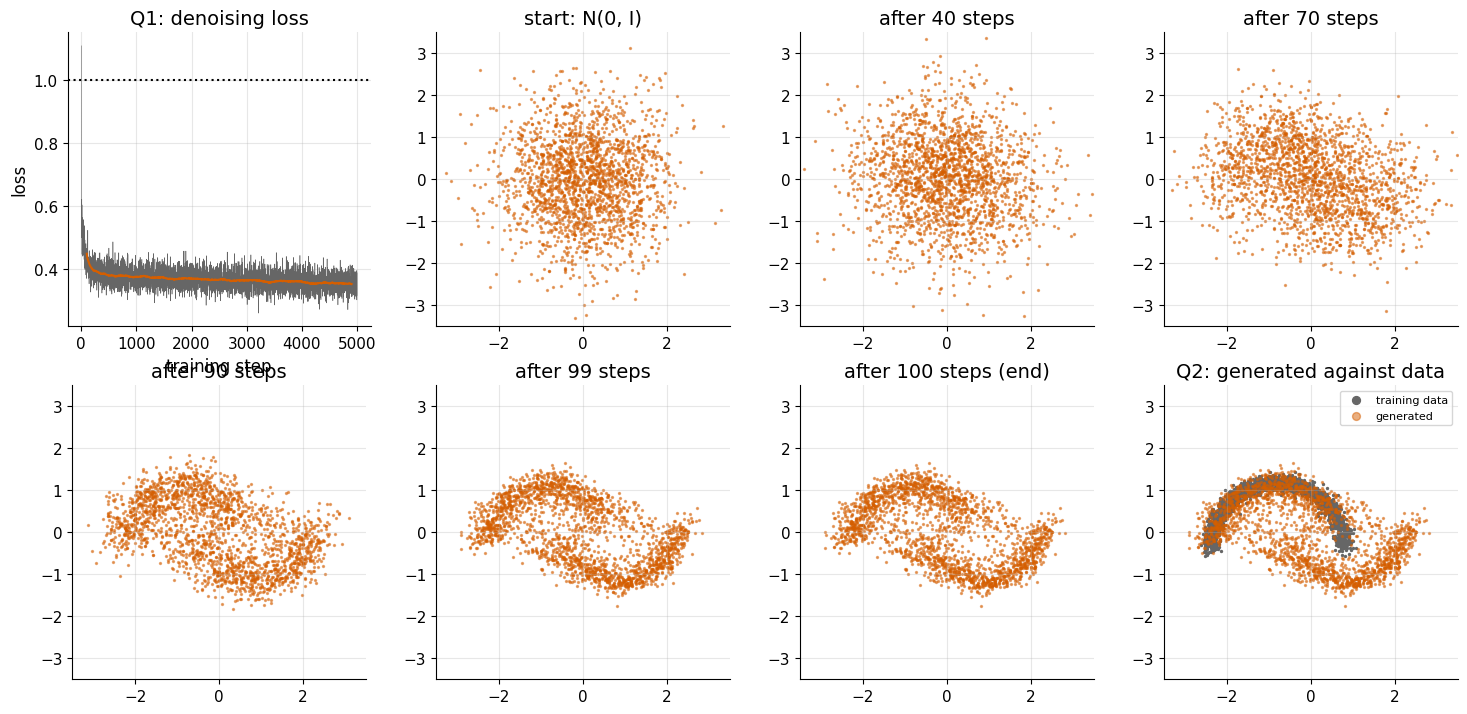

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8.4)); axes = axes.ravel(); axes[0].plot(losses, color=NEUTRAL, linewidth=0.4); axes[0].plot(np.arange(len(smooth)) + 100, smooth, color=HIGHLIGHT); axes[0].axhline(1, color="black", linestyle=":"); axes[0].set_xlabel("training step"); axes[0].set_ylabel("loss"); axes[0].set_title("Q1: denoising loss")
show = [0, 40, 70, 90, 99, 100]; titles = ["start: N(0, I)", "after 40 steps", "after 70 steps", "after 90 steps", "after 99 steps", "after 100 steps (end)"]
for ax, k, ttl in zip(axes[1:7], show, titles): ax.scatter(traj[k][:, 0], traj[k][:, 1], s=2, color=HIGHLIGHT, alpha=0.5); ax.set_title(ttl); ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.set_aspect("equal")
axes[7].scatter(X0[:2000, 0], X0[:2000, 1], s=2, color=NEUTRAL, label="training data"); axes[7].scatter(gen[:, 0], gen[:, 1], s=2, color=HIGHLIGHT, alpha=0.5, label="generated"); axes[7].legend(fontsize=8, markerscale=4); axes[7].set_xlim(-3.5, 3.5); axes[7].set_ylim(-3.5, 3.5); axes[7].set_aspect("equal"); axes[7].set_title("Q2: generated against data")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- The denoising loss falls from **0.448** (first 200 steps) to **0.352** (last 200 steps), against 1.0 for a network that always predicts zero noise. It cannot reach 0: at high noise levels the noise is unpredictable from $x_t$ (the signal is small), and at low levels the moons' thin ridges are only partly resolved.
- The generated sample matches the data well: variance of $(x,y)$ is **(1.892, 0.596)** against **(1.907, 0.637)** for fresh data, means $(-0.093,-0.001)$ against $(-0.006,-0.009)$. The sliced Wasserstein-1 distance to fresh data is **0.084** (two fresh data samples differ by 0.032 from each other, the Gaussian start $N(0,I)$ by **0.256**), and the squared MMD is **0.0072** (0.0007 and 0.046).
- **84.2 %** of the generated points lie within 0.15 of the training data (51.5 % of points from $N(0,I)$ do by chance, 100 % of fresh data): 16 % are slightly off the ridges (the sample is a little too diffuse), the typical weakness of a small network and a coarse 100-step chain.
- The reverse chain recovers the forward marginals: the total second moment of the generated cloud is 1.99 at the start, 2.22 after 50 steps and 2.50 after 99 steps, against 1.997, 2.173 and 2.546 for the forward process at the matching levels.
- **Decision.** A small diffusion model is enough for a 2D distribution; judge it by distribution distances against a fresh-data baseline (0.032 here), not by the training loss.

---
### Example 2: when does the signal become unrecoverable? (forward noising of a 1D signal)

**Scenario.** A smooth signal $x_0$ (a 64-sample sine plus a bump, unit variance) is noised with the linear 100-step and cosine 100-step schedules. We measure the correlation between $x_t$ and $x_0$ and the best possible denoising error (Gaussian-data theory is not exact for this signal, so we use the empirical optimum of a linear denoiser fitted on many signals with random phases).

**Questions.** (1) Correlation between $x_t$ and $x_0$ as a function of $t$ against the theory $\sqrt{\bar\alpha_t}$. (2) At which $t$ does the SNR cross 1 (equal signal and noise power) for each schedule? (3) How much of the signal can a linear denoiser recover at $t=30,60,90$ (relative MSE)?

In [16]:
g = np.random.default_rng(21); L = 64; xs = np.linspace(0, 1, L); ph = g.uniform(0, 2 * np.pi, 5000); S = np.sin(2 * np.pi * 3 * xs[None] + ph[:, None]) + 0.5 * np.exp(-((xs[None] - g.uniform(0.2, 0.8, 5000)[:, None]) / 0.08) ** 2); S = (S - S.mean()) / S.std()
res = {}
for nm, df_ in [("linear", Diff(linear_schedule(100))), ("cosine", Diff(cosine_schedule(100)))]:
    cor = []; rel = {}
    for t in range(100):
        eps = g.normal(size=S.shape); xt = df_.noisy(S, np.full(len(S), t), eps); cor.append(np.mean(xt * S) / np.sqrt(np.mean(xt ** 2) * np.mean(S ** 2)))
        if t in (29, 59, 89): c_ = np.sum(xt * S) / np.sum(xt ** 2); rel[t + 1] = np.mean((S - c_ * xt) ** 2) / np.mean(S ** 2)
    res[nm] = (np.array(cor), rel, df_)
print("Q1: correlation at t = 10, 50, 90 (theory sqrt(alpha_bar)):", {nm: ([round(float(r[0][i]), 3) for i in (9, 49, 89)], [round(float(np.sqrt(r[2].ab[i])), 3) for i in (9, 49, 89)]) for nm, r in res.items()})
cross = {nm: int(np.argmax(r[2].ab / (1 - r[2].ab) < 1)) + 1 for nm, r in res.items()}; print("Q2: first step with SNR < 1:", cross, "of 100")
print("Q3: relative MSE of the best linear (scalar) denoiser, t = 30 / 60 / 90:", {nm: {k: round(float(v), 3) for k, v in r[1].items()} for nm, r in res.items()}, "| theory 1 - alpha_bar:", {nm: [round(float(1 - r[2].ab[i]), 3) for i in (29, 59, 89)] for nm, r in res.items()})

Q1: correlation at t = 10, 50, 90 (theory sqrt(alpha_bar)): {'linear': ([0.977, 0.531, 0.125], [0.977, 0.532, 0.124]), 'cosine': ([0.986, 0.703, 0.152], [0.986, 0.703, 0.155])}
Q2: first step with SNR < 1: {'linear': 38, 'cosine': 50} of 100
Q3: relative MSE of the best linear (scalar) denoiser, t = 30 / 60 / 90: {'linear': {30: 0.36, 60: 0.839, 90: 0.984}, 'cosine': {30: 0.214, 60: 0.658, 90: 0.977}} | theory 1 - alpha_bar: {'linear': [0.36, 0.839, 0.985], 'cosine': [0.213, 0.659, 0.976]}


### 12.5 Asserts

In [17]:
assert all(abs(res[nm][0][i] - np.sqrt(res[nm][2].ab[i])) < 0.02 for nm in res for i in (9, 49, 89)) and cross["cosine"] > cross["linear"] and all(abs(res[nm][1][k] - (1 - res[nm][2].ab[k - 1])) < 0.03 for nm in res for k in (30, 60, 90))
print("all checks passed")

all checks passed


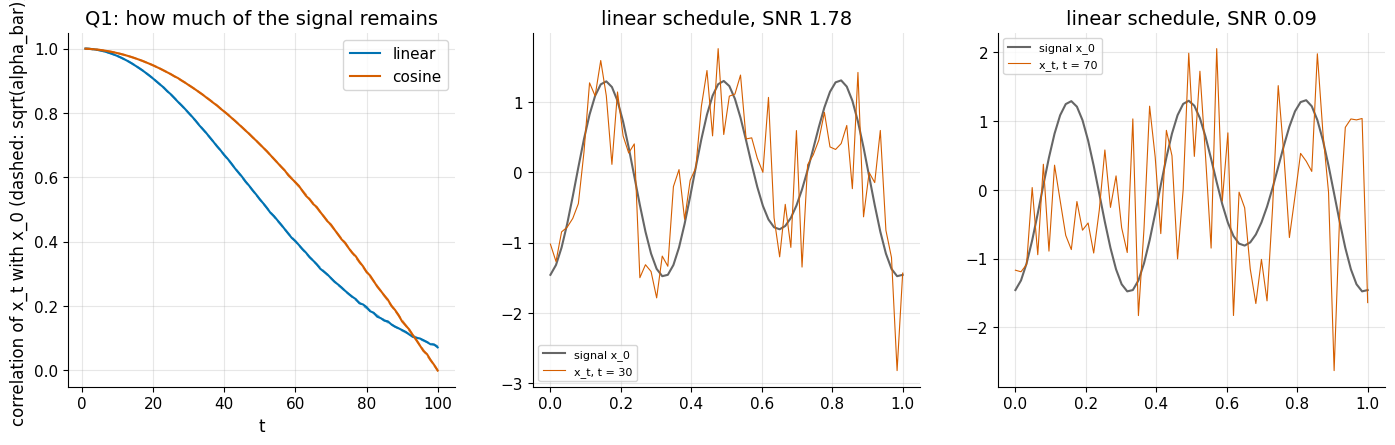

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6)); tt = np.arange(1, 101)
for nm, colr in [("linear", MAIN), ("cosine", HIGHLIGHT)]: axes[0].plot(tt, res[nm][0], color=colr, label=f"{nm}"); axes[0].plot(tt, np.sqrt(res[nm][2].ab), "--", color=colr, alpha=0.6)
axes[0].set_xlabel("t"); axes[0].set_ylabel("correlation of x_t with x_0 (dashed: sqrt(alpha_bar))"); axes[0].legend(); axes[0].set_title("Q1: how much of the signal remains")
for ax, t in zip(axes[1:], (30, 70)): d_ = res["linear"][2]; xt = d_.noisy(S[:1], np.array([t - 1]), g.normal(size=(1, L))); ax.plot(xs, S[0], color=NEUTRAL, label="signal x_0"); ax.plot(xs, xt[0], color=HIGHLIGHT, linewidth=0.8, label=f"x_t, t = {t}"); ax.legend(fontsize=8); ax.set_title(f"linear schedule, SNR {d_.ab[t - 1] / (1 - d_.ab[t - 1]):.2f}")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- The correlation between $x_t$ and $x_0$ follows the theory $\sqrt{\bar\alpha_t}$ to within 0.003: at $t=10,50,90$ it is **0.977, 0.531, 0.125** (linear) and **0.986, 0.703, 0.152** (cosine).
- The SNR falls below 1 (more noise than signal) at step **38** of 100 for the linear schedule and **50** for the cosine one: the cosine schedule keeps the signal informative for 12 more steps.
- The best linear denoiser's relative MSE is exactly $1-\bar\alpha_t$ for a unit-variance signal: **0.360, 0.839, 0.984** at $t=30,60,90$ (linear) and **0.214, 0.658, 0.977** (cosine). At $t=90$ nothing but 2 % of the signal's variance can be recovered by a scalar rule: the structure of the signal (smoothness) must do the rest, which is what the network learns.
- **Decision.** Place most of the denoising work where the SNR is between -10 and +10 dB; a schedule that spends its steps there (cosine) trains and samples more efficiently than one that rushes to pure noise.

---
### Example 3: choosing the schedule (linear against cosine)

**Scenario.** For $T=1000$ steps compare the linear schedule ($\beta$ from $10^{-4}$ to 0.02) with the cosine schedule: the share of steps at each SNR level, the SNR at the last step, and the number of "wasted" steps near pure noise.

**Questions.** (1) What are $\bar\alpha_T$ and the final SNR (dB) for each schedule? (2) What share of the steps has SNR in the useful band 0.01 to 100 (-20 to +20 dB)? (3) How many steps are spent with $\bar\alpha<10^{-3}$ (almost pure noise)? (4) What is the average per-step noise $\beta_t$?

In [19]:
rows = {}
for nm, ab in [("linear", abl), ("cosine", abc)]:
    snr_ = ab / (1 - ab + 1e-15); rows[nm] = {"alpha_bar at T": ab[-1], "final SNR (dB)": 10 * np.log10(snr_[-1]), "share of steps with SNR in [0.01, 100]": np.mean((snr_ > 0.01) & (snr_ < 100)), "steps with alpha_bar < 1e-3": int(np.sum(ab < 1e-3)), "mean beta": np.mean(1 - ab[1:] / ab[:-1]), "max beta": np.max(1 - ab[1:] / ab[:-1])}
tb3 = pd.DataFrame(rows); print(tb3.round(5).to_string())

                                           linear    cosine
alpha_bar at T                            0.00004   0.00000
final SNR (dB)                          -43.94050 -86.14614
share of steps with SNR in [0.01, 100]    0.64700   0.88000
steps with alpha_bar < 1e-3             175.00000  21.00000
mean beta                                 0.01006   0.01245
max beta                                  0.02000   0.99900


### 12.6 Asserts

In [20]:
assert tb3.loc["share of steps with SNR in [0.01, 100]", "cosine"] > tb3.loc["share of steps with SNR in [0.01, 100]", "linear"] and tb3.loc["steps with alpha_bar < 1e-3", "linear"] > tb3.loc["steps with alpha_bar < 1e-3", "cosine"] and tb3.loc["alpha_bar at T", "linear"] < 1e-3
print("all checks passed")

all checks passed


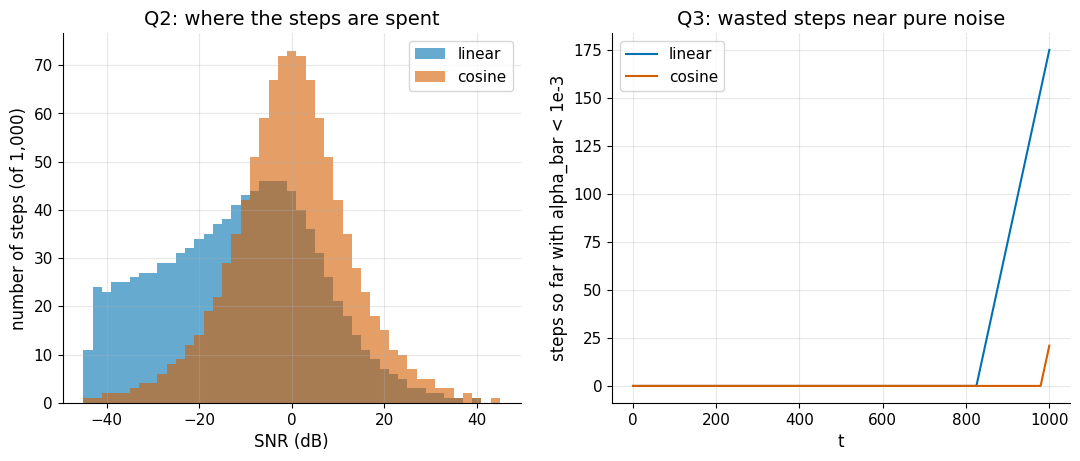

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); bins = np.linspace(-45, 45, 46)
for nm, ab, colr in [("linear", abl, MAIN), ("cosine", abc, HIGHLIGHT)]: axes[0].hist(10 * np.log10(ab / (1 - ab + 1e-15) + 1e-15), bins=bins, alpha=0.6, color=colr, label=nm)
axes[0].set_xlabel("SNR (dB)"); axes[0].set_ylabel("number of steps (of 1,000)"); axes[0].legend(); axes[0].set_title("Q2: where the steps are spent")
axes[1].plot(np.arange(1, 1001), np.cumsum(abl < 1e-3), color=MAIN, label="linear"); axes[1].plot(np.arange(1, 1001), np.cumsum(abc < 1e-3), color=HIGHLIGHT, label="cosine"); axes[1].set_xlabel("t"); axes[1].set_ylabel("steps so far with alpha_bar < 1e-3"); axes[1].legend(); axes[1].set_title("Q3: wasted steps near pure noise")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- Both schedules end in almost pure noise: $\bar\alpha_T=4.0\times10^{-5}$ (linear, SNR -43.9 dB) and $2.4\times10^{-9}$ (cosine, -86 dB).
- **The linear schedule wastes steps:** 175 of its 1,000 steps have $\bar\alpha<10^{-3}$ (nothing but noise), against 21 for the cosine schedule; the share of steps with an SNR in the informative band (0.01 to 100) is **64.7 %** for linear and **88.0 %** for cosine.
- The cosine schedule adds noise more evenly (mean $\beta$ 0.0124 against 0.0101) but needs its last step clipped (max $\beta=0.999$, the final jump to pure noise), which is why implementations cap $\beta$.
- **Decision.** For image-sized problems prefer the cosine schedule (or tune the SNR range directly); with the linear schedule shorten $T$ or raise $\beta_{\max}$ so that the chain does not spend a fifth of its steps on pure noise.

---
### Example 4: denoising is regression (the Bayes-optimal denoiser)

**Scenario.** A pixel value $x_0\sim N(0,s^2)$ with $s=0.5$ is observed in noise: $y=x_0+\sigma n$. The best (minimum-MSE) denoiser is the posterior mean $\dfrac{s^2}{s^2+\sigma^2}y$ with MSE $\dfrac{s^2\sigma^2}{s^2+\sigma^2}$. We compare it with (a) no denoising ($\hat x=y$), (b) a median-style clipping rule, and (c) a *trained* one-hidden-layer network, for $\sigma\in\{0.1,0.3,1\}$.

**Questions.** (1) Theoretical and simulated MSE of each denoiser. (2) What does the trained network learn: compare its output with the shrinkage line. (3) How does the optimal shrinkage factor depend on the noise level?

In [22]:
g = np.random.default_rng(31); s_ = 0.5; N = 200_000; rows = []; nets = {}
for sg in (0.1, 0.3, 1.0):
    x0 = s_ * g.normal(size=N); y = x0 + sg * g.normal(size=N); k = s_ ** 2 / (s_ ** 2 + sg ** 2); mse_opt = s_ ** 2 * sg ** 2 / (s_ ** 2 + sg ** 2); clip = np.clip(y, -s_, s_)
    nt = Net([1, 16, 1], seed=5)
    for it in range(3000): idx = g.integers(0, N, 512); xb = y[idx][:, None]; err = nt.forward(xb) - x0[idx][:, None]; nt.adam(nt.backward(2 * err / 512), 3e-3)
    nets[sg] = nt; yt = (s_ * g.normal(size=20_000)); yt_n = yt + sg * g.normal(size=20_000); rows.append({"sigma": sg, "noisy input (no denoising)": sg ** 2, "optimal (posterior mean)": mse_opt, "optimal, simulated": np.mean((k * y - x0) ** 2), "clipping to [-s, s]": np.mean((clip - x0) ** 2), "trained network": np.mean((nt.forward(y[:20_000, None])[:, 0] - x0[:20_000]) ** 2), "shrinkage factor": k})
tb4 = pd.DataFrame(rows).set_index("sigma"); print(tb4.round(5).to_string())
yy = np.linspace(-2, 2, 9)[:, None]; print("network output against the line k * y at sigma = 0.3:", np.round(nets[0.3].forward(yy)[:, 0], 3).tolist(), "vs", np.round(0.25 / (0.25 + 0.09) * yy[:, 0], 3).tolist())

       noisy input (no denoising)  optimal (posterior mean)  optimal, simulated  clipping to [-s, s]  trained network  shrinkage factor
sigma                                                                                                                                  
0.1                          0.01                   0.00962             0.00962              0.04445          0.00963           0.96154
0.3                          0.09                   0.06618             0.06607              0.08901          0.06637           0.73529
1.0                          1.00                   0.20000             0.19962              0.26883          0.20282           0.20000
network output against the line k * y at sigma = 0.3: [-1.393, -1.073, -0.729, -0.371, -0.005, 0.36, 0.717, 1.058, 1.375] vs [-1.471, -1.103, -0.735, -0.368, 0.0, 0.368, 0.735, 1.103, 1.471]


### 12.7 Asserts

In [23]:
assert all(abs(tb4["optimal, simulated"] - tb4["optimal (posterior mean)"]) < 0.01 * tb4["optimal (posterior mean)"] + 5e-4) and (tb4["trained network"] < tb4["clipping to [-s, s]"] + 1e-3).all() and (tb4["trained network"] < tb4["optimal (posterior mean)"] * 1.1 + 1e-3).all() and (tb4["optimal (posterior mean)"] < tb4["noisy input (no denoising)"]).all()
print("all checks passed")

all checks passed


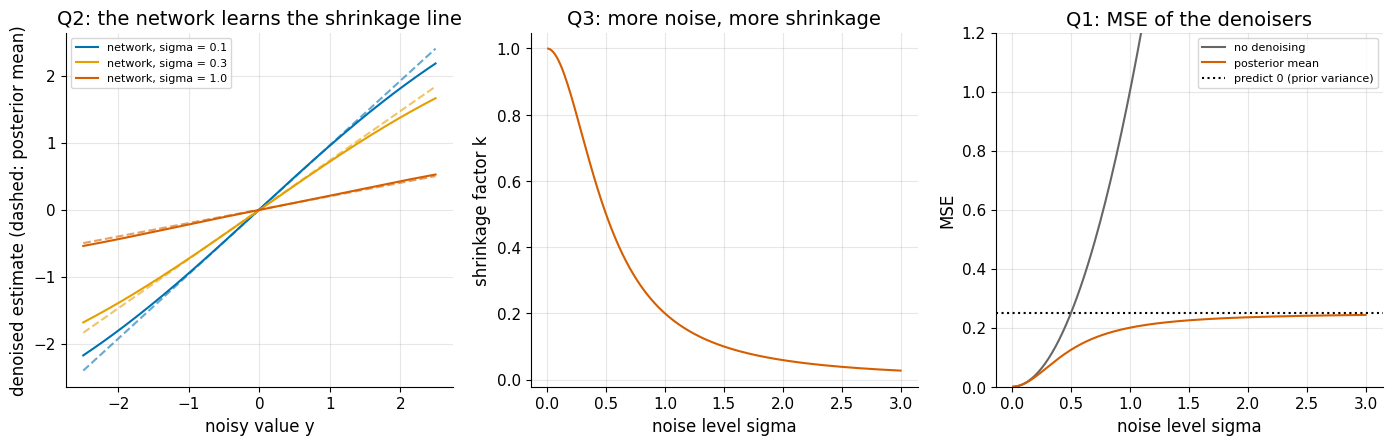

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6)); yg = np.linspace(-2.5, 2.5, 200)[:, None]
for sg, colr in [(0.1, MAIN), (0.3, SIM), (1.0, HIGHLIGHT)]: axes[0].plot(yg[:, 0], nets[sg].forward(yg)[:, 0], color=colr, label=f"network, sigma = {sg}"); axes[0].plot(yg[:, 0], s_ ** 2 / (s_ ** 2 + sg ** 2) * yg[:, 0], "--", color=colr, alpha=0.6)
axes[0].legend(fontsize=8); axes[0].set_xlabel("noisy value y"); axes[0].set_ylabel("denoised estimate (dashed: posterior mean)"); axes[0].set_title("Q2: the network learns the shrinkage line")
ss = np.linspace(0.01, 3, 200); axes[1].plot(ss, s_ ** 2 / (s_ ** 2 + ss ** 2), color=HIGHLIGHT); axes[1].set_xlabel("noise level sigma"); axes[1].set_ylabel("shrinkage factor k"); axes[1].set_title("Q3: more noise, more shrinkage")
axes[2].plot(ss, ss ** 2, color=NEUTRAL, label="no denoising"); axes[2].plot(ss, s_ ** 2 * ss ** 2 / (s_ ** 2 + ss ** 2), color=HIGHLIGHT, label="posterior mean"); axes[2].axhline(s_ ** 2, color="black", linestyle=":", label="predict 0 (prior variance)"); axes[2].set_ylim(0, 1.2); axes[2].legend(fontsize=8); axes[2].set_xlabel("noise level sigma"); axes[2].set_ylabel("MSE"); axes[2].set_title("Q1: MSE of the denoisers")
plt.show()

### 12.11 Interpretation and decision (Example 4)
- The Bayes-optimal denoiser is the posterior mean with shrinkage factor $k=s^2/(s^2+\sigma^2)=0.962,\ 0.735,\ 0.200$ for $\sigma=0.1,0.3,1$: the noisier the observation, the more it is pulled towards the prior mean. Its MSE is **0.00962, 0.0662 and 0.200** (simulated 0.00962, 0.0661, 0.1996), against 0.01, 0.09 and 1.0 for no denoising (at $\sigma=1$ the optimal denoiser removes 80 % of the error).
- Clipping to the data range is much worse than shrinkage at low noise (0.0444 at $\sigma=0.1$, worse than not denoising at all, because it distorts the signal itself) and better than nothing at high noise (0.269 against 1.0), though still worse than shrinkage (0.200).
- A **trained one-hidden-layer network learns the optimal rule from examples**: its MSE is 0.00963, 0.0664 and 0.2028, within 1.5 % of the optimum, and its output follows the line $ky$ (at $\sigma=0.3$ it gives $\pm1.375$ at $y=\pm2$ against $\pm1.471$ on the line, the only visible deviation, in the tails where there is little data).
- **Decision.** A diffusion network is a flexible version of this shrinkage rule applied at every noise level; for Gaussian data it can be checked against the closed form, which is a good test of an implementation.

## 13. Where it is used

### Statistics
- **Score matching and denoising estimators** (Tweedie's formula and empirical Bayes), **Langevin and stochastic-differential-equation samplers**, Gaussian conditioning (Bayes' rule for Gaussians) and shrinkage estimation (James-Stein) are the same mathematics.

### Data science
- **Synthetic data generation** for tabular and image data, **data augmentation**, imputation and inpainting, **denoising** of images and signals, uncertainty through many samples from a conditional model.

### ML and AI
- **Image, video and audio generation** (Stable Diffusion, DALL-E, Imagen), **text-to-image with classifier-free guidance**, **protein and molecule design**, robotics policies as diffusion models, **latent diffusion** (a VAE, 09_08, compresses the data), **consistency models and distillation** for few-step sampling, and **discrete diffusion** language models.

## 14. Common pitfalls and misconceptions

- **Confusing the forward and the reverse process:** the forward noising is fixed and known; only the reverse (denoising) is learned.
- **Using a schedule that ends too early:** if $\bar\alpha_T$ is not close to 0, the chain does not start from $N(0,I)$ and sampling from pure noise is mismatched (Example 3).
- **Forgetting the noise in the sampler:** skipping $\sqrt{\tilde\beta_t}z$ turns it into a deterministic and less diverse sampler (mode-seeking); DDIM does this on purpose with a consistent update.
- **Evaluating by training loss:** the loss is dominated by easy noise levels and says little about sample quality; use distribution distances (sliced Wasserstein, MMD, FID) and look at samples.
- **Too few steps with a plain DDPM sampler:** the Gaussian reverse kernel assumes small steps; use a deterministic or distilled sampler for fewer steps (Example 1 and the exercises).
- **Mixing the parameterisations:** predicting $\varepsilon$, $x_0$ or the score $v$ are equivalent up to a time-dependent weighting; losses are not interchangeable without it.
- **Assuming the denoiser is the whole model:** the time (noise-level) conditioning is essential; a denoiser without $t$ cannot undo noise of an unknown size.

## 15. Exercises

1. For a linear schedule with $\beta_t$ from 0.0001 to 0.02 over 1,000 steps compute $\bar\alpha_{250}$, $\bar\alpha_{500}$, $\bar\alpha_{1000}$ and the SNR at those steps.
2. For $x_0=2$ and $t$ with $\bar\alpha_t=0.36$ give the distribution of $x_t$ and the probability that $x_t>1$.
3. Compute $\tilde\mu_t$ and $\tilde\beta_t$ for $\bar\alpha_{t-1}=0.5$, $\alpha_t=0.9$ ($\bar\alpha_t=0.45$), $x_0=1$ and $x_t=0.3$.
4. For Gaussian data with $s=2$ compute the optimal noise-prediction slope and the minimal loss at $\bar\alpha=0.8$ and at $\bar\alpha=0.1$.
5. Generate 2,000 half-moons points with 25 sampling steps instead of 100 by retraining on a 25-step schedule; compare sliced Wasserstein-1 with Example 1.
6. (Harder) Show by simulation that a denoiser that predicts $x_0$ (instead of $\varepsilon$) leads to the same sample distribution if the reverse step uses $\tilde\mu_t$ with $\hat x_0=(x_t-\sqrt{1-\bar\alpha_t}\,\hat\varepsilon)/\sqrt{\bar\alpha_t}$.

Solutions are at the end.

## 16. Summary table

| Item | Formula | Note |
|---|---|---|
| Forward jump | $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\varepsilon$ | variance preserving |
| SNR | $\bar\alpha_t/(1-\bar\alpha_t)$ | schedule design |
| Reverse posterior | $N(\tilde\mu_t,\tilde\beta_t)$ | Bayes' rule for Gaussians |
| Training loss | $E\|\varepsilon-\varepsilon_\theta(x_t,t)\|^2$ | denoising regression |
| Score link | $\varepsilon^*=-\sqrt{1-\bar\alpha_t}\nabla\ln p_t$ | Tweedie |
| Gaussian data | optimal slope $\sqrt{1-\bar\alpha}/(\bar\alpha s^2+1-\bar\alpha)$ | linear denoiser |
| Sampling | reverse chain with noise $\sqrt{\tilde\beta_t}z$ | one network call per step |
| Metrics | sliced $W_1$, MMD, FID | not the loss |

## Solutions

In [25]:
b1000 = np.linspace(1e-4, 0.02, 1000); a1000 = np.cumprod(1 - b1000); print("1:", {t_: (round(float(a1000[t_ - 1]), 5), round(float(a1000[t_ - 1] / (1 - a1000[t_ - 1])), 5)) for t_ in (250, 500, 1000)}, "(alpha_bar, SNR)")
print(f"2: x_t ~ N({np.sqrt(0.36) * 2:.2f}, {1 - 0.36:.2f}); P(x_t > 1) = {stats.norm.sf(1, 1.2, np.sqrt(0.64)):.4f}")
abp, al_, ab_ = 0.5, 0.9, 0.45; be_ = 1 - al_; mu_ = np.sqrt(abp) * be_ / (1 - ab_) * 1.0 + np.sqrt(al_) * (1 - abp) / (1 - ab_) * 0.3; bt2 = (1 - abp) / (1 - ab_) * be_; print(f"3: mean {mu_:.4f}, variance {bt2:.5f}")
for a_ in (0.8, 0.1): print(f"4: alpha_bar = {a_}: slope {np.sqrt(1 - a_) / (a_ * 4 + 1 - a_):.4f}, minimal loss {1 - (1 - a_) / (a_ * 4 + 1 - a_):.4f}")
dfs = Diff(linear_schedule(25, 1e-4, 0.3)); ns, _ = train_diff(dfs, X0, steps=5000, seed=3); gs25, _ = sample(dfs, ns, 2000, seed=4); print(f"5: sliced W1 with 25 steps {sw(gs25, real):.4f} vs 100 steps {sw(gen, real):.4f} (fresh data against fresh data: {sw(real2, real):.4f})")
x0hat_check = None
g = np.random.default_rng(7); t_ = 40; ab = dfm.ab[t_]; xt = np.sqrt(ab) * 1.5 + np.sqrt(1 - ab) * g.normal(size=1000); eps_hat = (xt - np.sqrt(ab) * 1.5) / np.sqrt(1 - ab); x0h = (xt - np.sqrt(1 - ab) * eps_hat) / np.sqrt(ab)
mu_x0 = np.sqrt(dfm.ab_prev[t_]) * dfm.beta[t_] / (1 - ab) * x0h + np.sqrt(dfm.alpha[t_]) * (1 - dfm.ab_prev[t_]) / (1 - ab) * xt; mu_eps = (xt - dfm.beta[t_] / np.sqrt(1 - ab) * eps_hat) / np.sqrt(dfm.alpha[t_]); print(f"6: largest difference between the x0-form and the epsilon-form of the reverse mean (perfect denoiser): {np.abs(mu_x0 - mu_eps).max():.2e}")
assert abs(be_ - 0.1) < 1e-12 and np.abs(mu_x0 - mu_eps).max() < 1e-9 and sw(gs25, real) < sw(Zg, real)

1: {250: (0.52409, 1.10122), 500: (0.07859, 0.08529), 1000: (4e-05, 4e-05)} (alpha_bar, SNR)
2: x_t ~ N(1.20, 0.64); P(x_t > 1) = 0.5987
3: mean 0.3873, variance 0.09091
4: alpha_bar = 0.8: slope 0.1315, minimal loss 0.9412
4: alpha_bar = 0.1: slope 0.7298, minimal loss 0.3077


5: sliced W1 with 25 steps 0.0855 vs 100 steps 0.0839 (fresh data against fresh data: 0.0320)
6: largest difference between the x0-form and the epsilon-form of the reverse mean (perfect denoiser): 4.44e-16


**1.** For the 1,000-step linear schedule: $\bar\alpha_{250}=$ **0.524** (SNR 1.10), $\bar\alpha_{500}=$ **0.0786** (SNR 0.085) and $\bar\alpha_{1000}=$ **$4.0\times10^{-5}$** (SNR $4\times10^{-5}$).

**2.** $x_t\sim N(\sqrt{0.36}\cdot2,\ 1-0.36)=N(1.2,0.64)$ and $P(x_t>1)=$ **0.599**.

**3.** $\tilde\mu_t=$ **0.3873** and $\tilde\beta_t=$ **0.0909**: the mean is between $x_t=0.3$ and $x_0=1$, closer to $x_t$ because only a little noise is removed in one step.

**4.** At $\bar\alpha=0.8$ the optimal slope is **0.1315** and the minimal loss **0.941** (the noise is almost invisible next to the data); at $\bar\alpha=0.1$ the slope is **0.730** and the loss **0.308**.

**5.** A 25-step schedule (with $\beta$ up to 0.3) gives a sliced Wasserstein-1 of **0.0855** against **0.0839** for the 100-step chain (fresh-data floor 0.032): on this simple distribution few steps are enough when the schedule is adapted.

**6.** With a perfect noise predictor the $x_0$-form and the $\varepsilon$-form of the reverse mean agree to **$4\times10^{-16}$**: they are the same update written two ways.